# 도구 정의와 첫 호출 토큰

**이 노트북에서 할 일**

1. MCP 서버의 도구 정의가 모델에게 보낼 도구 명세가 되는 모양과 글자 수를 모델 없이 봅니다.
2. 입력 형식 모양·설명 길이·도구 수를 하나씩 바꾸며 명세 글자 수를 셉니다.
3. 같은 메시지로 첫 요청을 조건마다 한 번씩 보내, 도구 정의가 입력 토큰에 얼마나 더해지는지 봅니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 5절에서 조건 다섯에 첫 요청을 한 번씩 보냅니다.
도구는 알리기만 하고 부르지 않아서, 모델 요청은 모두 5번입니다.
요금표로 어림한 예상 비용은 다섯 요청을 합쳐 0.002달러 아래이고, 청구 금액이 아닙니다.

2~4절은 모델을 부르지 않고, 출력은 도구 정의와 도구 명세에서 센 값입니다.
서버는 실습 폴더 맨 위의 서버 파일 `course_server.py`를 씁니다.
2절은 04절처럼 서버를 자식 프로세스로 띄우고, 3·4절은 서버 파일을 이 커널 안에서 읽습니다.
노트북이 쓰는 파일은 없고, 걸린 시간은 재지 않았습니다.
앞에서 배운 함수 다섯은 도구 파일 `connect_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
패키지 fastmcp 4.0.3, mcp 2.2.0, python-dotenv 1.2.3도 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었고, 다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절을 읽습니다.
도구 정의가 도구 명세가 되는 모양과, 무엇을 바꾸면 명세 글자 수가 달라지는지 보는 자리입니다.
5절은 실제 모델에 첫 요청을 보내는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch28-mcp`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 서버 파일 course_server.py 도구 정의 lookup_policy에서 파란 상자 MCPAdapter list_tools stdio 연결, 노란 상자 StructuredTool 입력 형식 dict, 파란 상자 convert_to_openai_tool을 지나 노란 상자 도구 명세로 화살표가 이어집니다. 명세 상자에는 type function, 칸 name · description, 칸 parameters = 입력 형식 True가 적혀 있고, 거기서 점선 둘이 나란히 놓인 노란 상자 spec_length 명세 글자 수 252와 노란 상자 bind_tools 요청에 실을 도구 칸 명세와 같음 True로 가는 그림](attachment:05-1-도구-정의가-도구-명세가-되기까지.png)

위에서 아래로 읽습니다.
초록 상자는 서버 파일이고, 파란 상자는 우리가 부른 클래스와 함수입니다.
노란 상자는 노트북 2절 출력으로 확인한 값입니다.
맨 아래 점선 둘은 같은 명세를 두 쪽에서 본 갈래로, 글자 수를 센 쪽과 모델 객체에 알린 쪽입니다.
모델은 5절에서만 부르고, 이 그림에는 모델 상자를 두지 않았습니다.
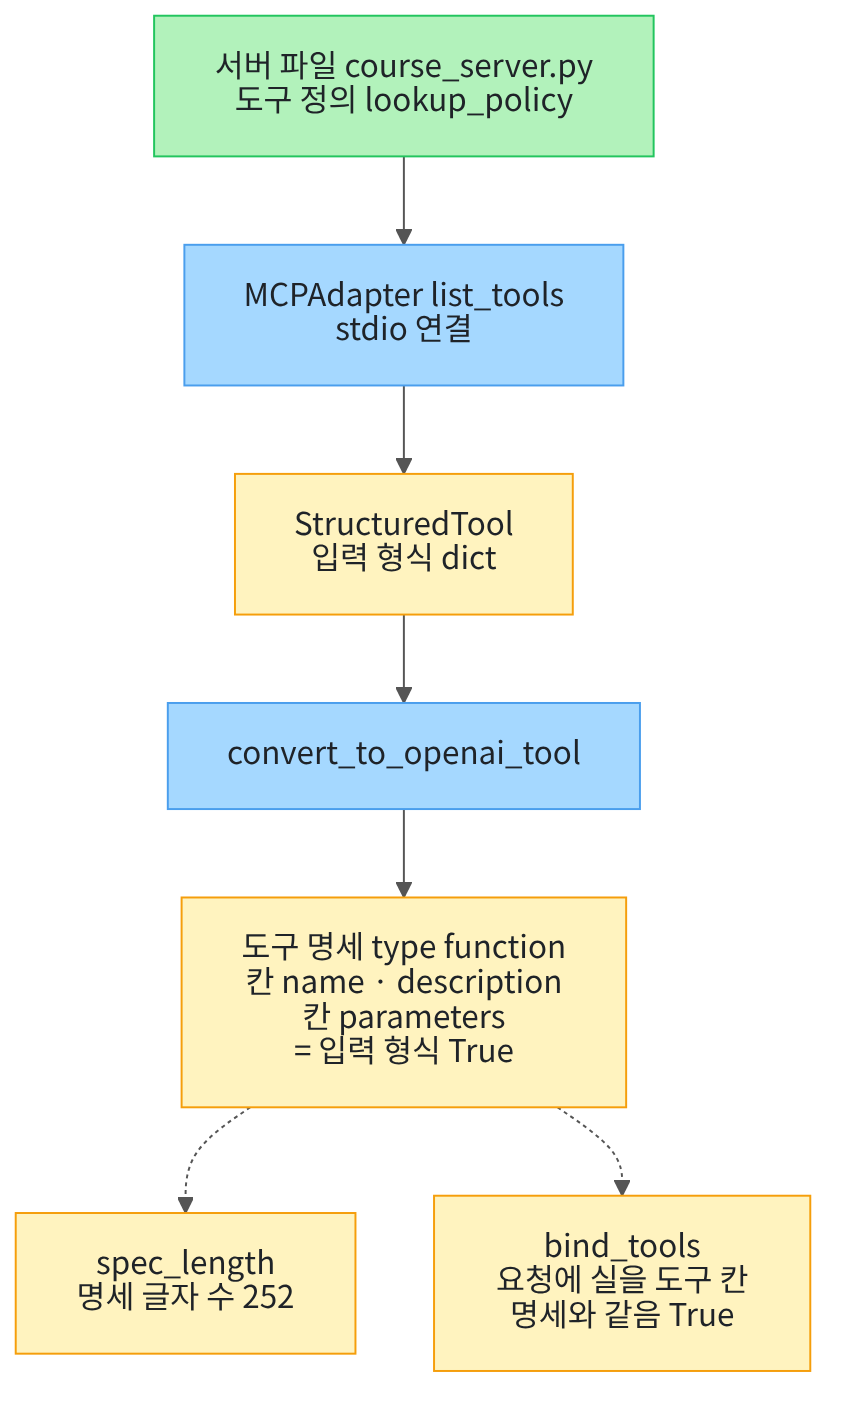

## 1. 준비

04절은 MCP 도구를 LangChain 도구로 바꿔 에이전트에 붙였습니다.
이 절은 그 도구 정의가 모델에게 가는 요청에 어떤 모양으로 실리는지 봅니다.
그리고 도구를 부르기 전 첫 요청의 입력 토큰에 얼마나 더해지는지 셉니다.

첫 셀은 패키지 여섯을 설치하고 설치된 판 번호를 출력합니다.
04절과 달리 langgraph와 psutil은 쓰지 않아 설치하지 않습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain[mcp]==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "fastmcp==4.0.3" "mcp==2.2.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("fastmcp:", version("fastmcp"))
print("mcp:", version("mcp"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
fastmcp: 4.0.3
mcp: 2.2.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`, `langchain-core: 1.6.2`, `fastmcp: 4.0.3`이 보입니다.
여섯 판 모두 실습 폴더 잠금과 같습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
04절처럼 모듈 `langchain.mcp`는 베타 경고 한 종류만 끄고 가져옵니다.
모듈 `json`과 함수 `convert_to_openai_tool`은 Ch 19에서 도구 명세를 볼 때 쓴 이름입니다.
모듈 `runpy`는 01·02절처럼 서버 파일을 이 커널에서 읽을 때 씁니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(langchain.mcp는 베타 경고 한 종류만 끄고 가져옵니다)
import json
import runpy
import warnings
from langchain_core._api import LangChainBetaWarning
warnings.filterwarnings("ignore", category=LangChainBetaWarning)
from langchain.mcp import MCPAdapter
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage, SystemMessage
from langchain.tools import tool
from langchain_core.utils.function_calling import convert_to_openai_tool
from fastmcp import FastMCP
# 01·03절과 앞 챕터에서 배운 함수 다섯은 도구 파일에서 가져옵니다
from connect_tools import estimate_cost, names_of, spec_length, stdio_config, tool_call_names

print("도구 파일에서 가져온 함수:", "estimate_cost, names_of, spec_length, stdio_config, tool_call_names")

도구 파일에서 가져온 함수: estimate_cost, names_of, spec_length, stdio_config, tool_call_names


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: estimate_cost, names_of, spec_length, stdio_config, tool_call_names`가 보입니다.
함수 `spec_length`는 Ch 19 03절에서 만든 함수로, 도구 목록의 명세 글자 수를 모두 더합니다.
이 절부터 도구 파일에서 가져오고, 설명 주석과 본문은 Ch 19 03절 노트북 셀과 글자까지 같습니다.
나머지 넷은 04절에서처럼 01·03절과 Ch 19 04절, Ch 6 06절에서 배운 함수입니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
모델 요청은 5절의 요청 셀 다섯에서만 나갑니다.

## 2. 도구 정의가 도구 명세가 되기까지

01절에서 서버가 알린 도구 정의에는 이름·설명·입력 형식이 들어 있었습니다.
04절은 그 정의를 받아 LangChain 도구로 바꿨습니다.
이 절은 바꾼 도구를 모델에게 보낼 도구 명세로 만들어, 그 모양과 글자 수를 봅니다.
먼저 01절 2절과 같은 셀로 서버 파일의 위치를 찾습니다.

In [5]:
# 작업 폴더에서 본 서버 파일의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["../course_server.py", "course_server.py", "labs/part6/ch28-mcp/course_server.py"]
server_file = None
for candidate in candidates:
    if os.path.exists(candidate):
        server_file = candidate
        break
print("서버 파일을 찾았는가:", server_file is not None)
print("고른 파일 위치:", server_file)
assert server_file is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

서버 파일을 찾았는가: True
고른 파일 위치: labs/part6/ch28-mcp/course_server.py


**결과 읽기** — 출력 줄 `서버 파일을 찾았는가: True`가 보입니다.
교재 출력은 프로젝트 맨 위에서 실행해 셋째 후보 `labs/part6/ch28-mcp/course_server.py`를 골랐습니다.
`notebooks/` 폴더에서 열면 첫 후보 `../course_server.py`가 골라집니다.

다음 셀은 03절 2절과 같은 셀로, 서버를 조용히 띄우는 환경 변수 셋을 딕셔너리로 만듭니다.

In [6]:
# 자식 프로세스로 띄운 FastMCP 서버가 시작 안내와 새 판 확인을 하지 않게 하는 환경 변수 셋입니다
quiet_env = {
    "FASTMCP_SHOW_SERVER_BANNER": "false",
    "FASTMCP_CHECK_FOR_UPDATES": "off",
    "FASTMCP_LOG_LEVEL": "WARNING",
}
print("조용히 하는 이름:", list(quiet_env))

조용히 하는 이름: ['FASTMCP_SHOW_SERVER_BANNER', 'FASTMCP_CHECK_FOR_UPDATES', 'FASTMCP_LOG_LEVEL']


**결과 읽기** — 라벨 `조용히 하는 이름:` 뒤에 이름 셋이 보입니다.
03절에서 본 것처럼, 시작 안내와 새 판 확인을 끄고 기록 수준을 올리는 이름입니다.

다음 셀은 04절 2절처럼 설정 한 벌을 클래스 `MCPAdapter`에 넘겨, 서버 파일의 도구를 받습니다.
받은 도구의 입력 형식도 함께 출력합니다.

In [7]:
# 03절 함수 stdio_config로 만든 설정을 MCPAdapter에 넘겨, 서버 파일의 도구를 LangChain 도구로 받습니다
course_config = stdio_config(server_file, quiet_env)
adapter = MCPAdapter(course_config)
mcp_tools = await adapter.list_tools()
policy_tool = mcp_tools[0]
print("받은 도구 이름:", names_of(mcp_tools))
print("입력 형식:", policy_tool.args_schema)

받은 도구 이름: ['lookup_policy']
입력 형식: {'type': 'object', 'additionalProperties': False, 'properties': {'topic': {'type': 'string'}}, 'required': ['topic']}


**결과 읽기** — 출력 줄 `받은 도구 이름: ['lookup_policy']`가 보입니다.
라벨 `입력 형식:` 뒤의 딕셔너리는 04절 2절에서 본 입력 형식과 같은 글입니다.
칸 `'additionalProperties': False`는 적힌 칸 `topic` 말고 다른 칸은 받지 않는다는 표시입니다.
01절 4절에서 서버의 입력 형식에 이 칸이 있는 것을 보았습니다.

다음 셀은 이 도구 하나를 모델에게 보낼 도구 명세로 만듭니다.
Ch 19 01절에서 쓴 함수 `convert_to_openai_tool`은 도구 하나를 받아 명세 딕셔너리를 내놓습니다.
Ch 19 03절처럼, 이 딕셔너리를 이 절에서도 도구 명세라고 부릅니다.

In [8]:
# 바꾼 도구 하나를 모델에게 보낼 도구 명세 딕셔너리로 만들고, 칸을 봅니다(Ch 19 01절 convert_to_openai_tool)
policy_spec = convert_to_openai_tool(policy_tool)
spec_function = policy_spec["function"]
print("명세의 칸:", list(policy_spec))
print("칸 function 안의 칸:", list(spec_function))
print("이름:", spec_function["name"])
print("설명:", spec_function["description"])
print("parameters 칸이 입력 형식과 같은가:", spec_function["parameters"] == policy_tool.args_schema)

명세의 칸: ['type', 'function']
칸 function 안의 칸: ['name', 'description', 'parameters']
이름: lookup_policy
설명: 자료실 규정을 조회합니다. topic은 대출, 운영, 연체 중 하나입니다.
parameters 칸이 입력 형식과 같은가: True


**결과 읽기** — 출력 줄 `명세의 칸: ['type', 'function']`과 `칸 function 안의 칸: ['name', 'description', 'parameters']`가 보입니다.
이름과 설명은 서버 파일 도구의 이름과 독스트링 글 그대로입니다.
출력 줄 `parameters 칸이 입력 형식과 같은가: True`로, 서버가 보낸 입력 형식이 그대로 실립니다.

04절은 모델에게 보내는 도구 정의에 입력 형식 딕셔너리가 어떻게 실리는지 05절에서 본다고 했습니다.
바꾼 MCP 도구의 입력 형식 딕셔너리는 명세의 칸 `parameters`에 그대로 들어갑니다.
서버 파일 도구의 출력 형식(02절 6절)은 명세의 칸에 없습니다.

다음 셀은 이 명세를 JSON 글로 바꿔 글자 수를 셉니다.
Ch 19 03절의 함수 `spec_length`도 같은 방법으로 세므로, 두 값을 견줍니다.

In [9]:
# 명세를 JSON 글로 바꿔 글자 수를 세고, Ch 19 03절 함수 spec_length로 센 값과 견줍니다
policy_text = json.dumps(policy_spec, ensure_ascii=False)
mcp_length = spec_length(mcp_tools)
print("명세 JSON 글:")
print(policy_text)
print("글자 수:", len(policy_text))
print("spec_length로 센 글자 수:", mcp_length)

명세 JSON 글:
{"type": "function", "function": {"name": "lookup_policy", "description": "자료실 규정을 조회합니다. topic은 대출, 운영, 연체 중 하나입니다.", "parameters": {"type": "object", "additionalProperties": false, "properties": {"topic": {"type": "string"}}, "required": ["topic"]}}}
글자 수: 252
spec_length로 센 글자 수: 252


**결과 읽기** — 라벨 줄 `명세 JSON 글:` 아래에 명세 한 줄이 보입니다.
출력 줄 `글자 수: 252`와 `spec_length로 센 글자 수: 252`가 같습니다.
도구가 하나라서, 함수 `spec_length`가 더한 값도 명세 하나의 글자 수입니다.

JSON 글에서는 파이썬의 `False`가 `false`로 바뀌고, 따옴표도 큰따옴표가 됩니다.
Ch 19 03절에서 본 것처럼 이 글자 수는 토큰 수와 다릅니다.
모델이 이 명세를 몇 토큰으로 세는지는 5절에서 요청을 보내 봅니다.

다음 셀은 모델 객체에 이 도구를 알리고, 요청에 실을 도구 칸을 봅니다.
Ch 19 04절처럼 메서드 `bind_tools`는 도구 목록을 받은 새 모델 객체를 내놓습니다.
속성 `kwargs["tools"]`에 요청에 실을 도구 칸이 들어 있고, 이 셀은 요청을 보내지 않습니다.

In [10]:
# 모델 객체에 MCP 도구를 알리고, 요청에 실을 도구 칸이 앞 셀의 명세와 같은지 봅니다(요청은 아직 없음)
mcp_model = model.bind_tools(mcp_tools)
bound_tools = mcp_model.kwargs["tools"]
print("알린 도구 수:", len(bound_tools))
print("앞 셀의 명세와 같은가:", bound_tools[0] == policy_spec)

알린 도구 수: 1
앞 셀의 명세와 같은가: True


**결과 읽기** — 출력 줄 `알린 도구 수: 1`과 `앞 셀의 명세와 같은가: True`가 보입니다.
메서드 `bind_tools`도 앞 셀과 같은 명세를 만들어 요청에 실을 준비를 합니다.
모델 객체 `mcp_model`은 5절에서 첫 요청을 보낼 때 다시 씁니다.

실제 요청에서는 이 딕셔너리가 JSON 글로 바뀌어 서비스에 갑니다.
그때 띄어쓰기나 한글을 적는 방법이 이 셀과 다를 수 있어, 글자 수를 요청 크기로 읽지는 않습니다.

## 3. 입력 형식 모양만 다른 직접 도구

MCP 도구의 명세에는 칸 `additionalProperties`가 있었습니다.
Ch 19처럼 `@tool` 줄로 직접 만든 도구의 명세에도 이 칸이 있을까요?
이름과 설명을 똑같이 둔 직접 도구를 만들어 견줍니다.
직접 도구의 몸통이 쓸 규정 글은 서버 파일에서 가져옵니다.
다음 셀은 02절 6절처럼 서버 파일을 이 커널에서 실행해, 서버 객체와 규정 딕셔너리를 받습니다.

In [11]:
# 서버 파일을 실행해 서버 객체와 규정 딕셔너리를 받습니다(02절 6절처럼 runpy.run_path로 읽고, 파일은 고치지 않습니다)
server_names = runpy.run_path(server_file)
server = server_names["mcp"]
policies = server_names["POLICIES"]
print("서버 이름:", server.name)
print("규정 주제:", list(policies))

서버 이름: 교육센터 자료실
규정 주제: ['대출', '운영', '연체']


**결과 읽기** — 출력 줄 `서버 이름: 교육센터 자료실`과 `규정 주제: ['대출', '운영', '연체']`가 보입니다.
변수 `server`는 서버 파일이 만든 서버 객체이고, 변수 `policies`는 서버 파일의 규정 딕셔너리입니다.
파일을 실행해 이름을 받았을 뿐이라, 서버 파일은 그대로입니다.

다음 셀은 서버 파일 도구와 이름·설명이 같은 도구를 직접 만듭니다.
셀의 `@tool("lookup_policy")` 줄은 아래 함수를 이름이 lookup_policy인 LangChain 도구로 만듭니다.
Ch 19 04절처럼 도구 이름을 따로 정해, 파이썬 함수 이름 `direct_lookup`과 다르게 둡니다.
몸통은 규정 딕셔너리에서 주제어의 글을 찾는 한 줄입니다.

In [12]:
# 서버 파일 도구와 이름·설명이 같은 도구를 Ch 19처럼 @tool 줄로 직접 만듭니다
@tool("lookup_policy")
def direct_lookup(topic: str):
    """자료실 규정을 조회합니다. topic은 대출, 운영, 연체 중 하나입니다."""
    return policies[topic]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
매개변수 힌트 `topic: str`과 독스트링은 서버 파일 도구와 같은 글입니다.
서버 파일 도구의 내놓는 값 힌트는 명세에 실리지 않아 적지 않았습니다.

다음 셀은 직접 도구의 명세를 만들어, MCP 도구의 명세와 견줍니다.
실행 전에 예상해 봅니다.
이름과 설명이 같다면, 두 명세의 글자 수도 같을까요?

In [13]:
# 직접 도구의 명세를 만들고, MCP 도구 명세와 이름·설명·칸 parameters·글자 수를 견줍니다
direct_function = convert_to_openai_tool(direct_lookup)["function"]
direct_length = spec_length([direct_lookup])
print("이름이 같은가:", direct_function["name"] == spec_function["name"])
print("설명이 같은가:", direct_function["description"] == spec_function["description"])
print("직접 도구 parameters 칸:", direct_function["parameters"])
print("직접 도구 명세 글자 수:", direct_length)
print("MCP 도구 명세 글자 수:", mcp_length)
print("MCP 쪽이 긴 글자 수:", mcp_length - direct_length)

이름이 같은가: True
설명이 같은가: True
직접 도구 parameters 칸: {'properties': {'topic': {'type': 'string'}}, 'required': ['topic'], 'type': 'object'}
직접 도구 명세 글자 수: 221
MCP 도구 명세 글자 수: 252
MCP 쪽이 긴 글자 수: 31


**결과 읽기** — 출력 줄 `이름이 같은가: True`와 `설명이 같은가: True`가 보입니다.
라벨 `직접 도구 parameters 칸:` 뒤의 딕셔너리에는 칸 `additionalProperties`가 없습니다.
출력 줄 `직접 도구 명세 글자 수: 221`과 `MCP 도구 명세 글자 수: 252`가 보입니다.
출력 줄 `MCP 쪽이 긴 글자 수: 31`은 쉼표와 띄어쓰기를 넣은 `, "additionalProperties": false`의 글자 수와 같습니다.

칸 차례도 다릅니다. 직접 도구는 `properties`부터, MCP 도구는 `type`부터 적혀 있습니다.
이름과 설명이 같아도, 서버가 보낸 입력 형식을 그대로 싣는 MCP 도구는 명세가 조금 깁니다.
이 차이가 첫 요청의 입력 토큰에도 나타나는지는 5절에서 봅니다.

## 4. 설명 길이와 도구 수

Ch 19 03절에서는 설명을 늘리면 명세 글자 수가 늘었고, 도구가 늘수록 글자 수도 늘었습니다.
MCP 도구도 같은지 서버 쪽에서 두 가지를 하나씩 바꿔 봅니다.
먼저 설명만 두 문장 늘린 도구를 붙인 연습 서버를 만듭니다.
셀의 `@longer.tool` 줄은 02절처럼 아래 함수를 서버 `longer`의 도구로 등록합니다.

In [14]:
# 설명만 두 문장 늘린 lookup_policy 도구를 붙인 연습 서버를 만듭니다(이름·매개변수 힌트는 서버 파일과 같음)
longer = FastMCP("설명을 늘린 자료실")

@longer.tool
def lookup_policy(topic: str):
    """자료실 규정을 조회합니다. topic은 대출, 운영, 연체 중 하나입니다. 대출·운영·연체 규정을 물을 때 씁니다. 그 주제의 규정 글 한 문장을 내놓습니다."""
    return policies[topic]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
독스트링의 앞 두 문장은 서버 파일 도구와 같습니다.
언제 쓰는지와 내놓는 값을 적은 두 문장을 뒤에 더했고, 네 문장을 한 줄에 적었습니다.

다음 셀은 연습 서버를 클래스 `MCPAdapter`에 넘겨 도구를 받습니다.
01절에서 `Client`에 서버 객체를 넘긴 것처럼, 서버 객체를 넘기면 메모리 연결로 붙습니다.
자식 프로세스를 띄우지 않아, 설정 딕셔너리가 필요 없습니다.

In [15]:
# 연습 서버 객체를 메모리 연결로 MCPAdapter에 넘겨 도구를 받고, 서버 파일 도구와 견줍니다
long_adapter = MCPAdapter(longer)
long_tools = await long_adapter.list_tools()
long_tool = long_tools[0]
print("받은 도구 이름:", names_of(long_tools))
print("입력 형식이 같은가:", long_tool.args_schema == policy_tool.args_schema)
print("설명이 같은가:", long_tool.description == policy_tool.description)

받은 도구 이름: ['lookup_policy']
입력 형식이 같은가: True
설명이 같은가: False


**결과 읽기** — 출력 줄 `받은 도구 이름: ['lookup_policy']`와 `입력 형식이 같은가: True`가 보입니다.
출력 줄 `설명이 같은가: False`로, 서버 파일 도구와 다른 것은 설명뿐입니다.

다음 셀은 늘어난 명세 글자 수와 늘어난 설명 글자 수를 견줍니다.
실행 전에 예상해 봅니다.
설명이 늘어난 만큼만 명세가 늘어날까요?

In [16]:
# 설명을 늘린 판의 명세 글자 수를 세고, 늘어난 명세 글자 수와 늘어난 설명 글자 수를 견줍니다
long_length = spec_length(long_tools)
added_spec = long_length - mcp_length
added_description = len(long_tool.description) - len(policy_tool.description)
print("설명을 늘린 판 명세 글자 수:", long_length)
print("늘어난 명세 글자 수:", added_spec)
print("늘어난 설명 글자 수:", added_description)
print("두 수가 같은가:", added_spec == added_description)

설명을 늘린 판 명세 글자 수: 299
늘어난 명세 글자 수: 47
늘어난 설명 글자 수: 47
두 수가 같은가: True


**결과 읽기** — 출력 줄 `설명을 늘린 판 명세 글자 수: 299`가 보입니다.
출력 줄 `늘어난 명세 글자 수: 47`과 `늘어난 설명 글자 수: 47`이 같고, `두 수가 같은가: True`입니다.
명세의 다른 칸은 그대로라, 늘어난 글자는 모두 설명에서 왔습니다.

다음은 도구 수를 바꿔 봅니다.
3절에서 받은 서버 객체 `server`에 도구 둘을 더 붙입니다.
파일은 고치지 않고, 이 커널 안의 서버 객체에만 붙습니다.

셀의 `@server.tool` 줄은 아래 함수를 서버 객체 `server`의 도구로 등록합니다.
첫째 도구는 규정 글에 낱말이 든 주제어를 찾습니다.

In [17]:
# 서버 객체에 규정 글에서 낱말이 든 주제어를 찾는 도구를 더 붙입니다(서버 파일은 그대로입니다)
@server.tool
def search_topics(word: str):
    """규정 글에 낱말이 든 주제어를 찾습니다. word에는 찾을 낱말을 넣습니다."""
    found = []
    for topic in policies:
        if word in policies[topic]:
            found.append(topic)
    return found

**결과 읽기** — 정의 셀이라 출력이 없습니다.
몸통은 규정 딕셔너리의 주제어를 차례로 보며, 규정 글에 낱말이 든 주제어를 모읍니다.
이 절은 도구를 부르지 않고, 도구 정의만 봅니다.

다음 셀은 인자가 없는 도구 하나를 같은 서버 객체에 더 붙입니다.

In [18]:
# 같은 서버 객체에 규정 주제어 목록을 알려 주는, 인자 없는 도구를 더 붙입니다
@server.tool
def show_topics():
    """자료실 규정의 주제어 목록을 알려 줍니다."""
    return list(policies)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
몸통은 규정 딕셔너리의 주제어를 목록으로 내놓습니다.

다음 셀은 도구 셋이 붙은 서버 객체를 메모리 연결로 넘겨 도구를 받습니다.
첫 도구의 명세가 2절에서 받은 도구의 명세와 같은지도 봅니다.

In [19]:
# 도구 셋이 붙은 서버 객체를 메모리 연결로 넘겨 도구를 받고, 첫 도구 명세를 2절 명세와 견줍니다
wide_adapter = MCPAdapter(server)
wide_tools = await wide_adapter.list_tools()
first_wide_spec = convert_to_openai_tool(wide_tools[0])
print("받은 도구 이름:", names_of(wide_tools))
print("첫 도구 명세가 2절 명세와 같은가:", first_wide_spec == policy_spec)

받은 도구 이름: ['lookup_policy', 'search_topics', 'show_topics']
첫 도구 명세가 2절 명세와 같은가: True


**결과 읽기** — 출력 줄 `받은 도구 이름: ['lookup_policy', 'search_topics', 'show_topics']`가 보입니다.
출력 줄 `첫 도구 명세가 2절 명세와 같은가: True`로, 연결 방법이 달라도 같은 도구는 같은 명세였습니다.
2절은 서버를 자식 프로세스로 띄웠고, 이 셀은 같은 커널 안에서 메모리 연결로 붙였습니다.

다음 셀은 도구를 하나·둘·셋으로 늘리며 명세 글자 수를 셉니다.
Ch 19 03절처럼 슬라이싱 `[:count]`로 목록 앞에서부터 도구를 고릅니다.

In [20]:
# 도구를 하나·둘·셋으로 늘리며 명세 글자 수를 셉니다
for count in [1, 2, 3]:
    chosen_tools = wide_tools[:count]
    print("도구 수:", count, "| 명세 글자 수:", spec_length(chosen_tools))

도구 수: 1 | 명세 글자 수: 252
도구 수: 2 | 명세 글자 수: 503
도구 수: 3 | 명세 글자 수: 685


**결과 읽기** — 명세 글자 수는 도구 하나에서 `252`, 둘에서 `503`, 셋에서 `685`입니다.
도구 하나일 때의 252는 2절에서 센 MCP 도구 명세 글자 수와 같습니다.
둘째 도구 `search_topics`는 251자, 셋째 도구 `show_topics`는 182자를 더했습니다.
인자가 없는 셋째 도구는 명세가 짧아, 도구마다 더해지는 글자 수가 다릅니다.

## 5. 첫 요청의 입력 토큰

이제 실제 모델에 첫 요청을 보내, 도구 명세가 입력 토큰에 얼마나 더해지는지 셉니다.
첫 요청은 도구를 한 번도 부르기 전, 대화를 시작하는 모델 요청입니다.
도구 목록을 알린 모델 객체는 요청마다 도구 명세를 함께 싣습니다.
이 절은 도구를 알리기만 하고 부르지 않아서, 조건마다 요청은 한 번입니다.

다음 셀은 첫 요청에 실을 메시지 둘을 만듭니다.
시스템 메시지 글과 질문은 04절 에이전트에 준 글과 같습니다.
Ch 6 02절에서 본 메시지 객체 `SystemMessage`와 `HumanMessage`로 만듭니다.

In [21]:
# 04절 에이전트와 같은 시스템 메시지 글과 질문으로, 첫 요청에 실을 메시지 둘을 만듭니다
agent_rule = "교육센터 자료실 규정 질문에는 도구로 규정을 찾아, 찾은 글만 근거로 한국어 한 문장으로 답하세요."
question = "교육센터 자료실은 토요일에 몇 시까지 운영하나요?"
first_messages = [SystemMessage(content=agent_rule), HumanMessage(content=question)]
print("첫 요청 메시지 수:", len(first_messages))
print("첫 메시지 종류:", type(first_messages[0]).__name__)

첫 요청 메시지 수: 2
첫 메시지 종류: SystemMessage


**결과 읽기** — 출력 줄 `첫 요청 메시지 수: 2`와 `첫 메시지 종류: SystemMessage`가 보입니다.
설치판 소스를 보면, 04절의 에이전트도 시스템 메시지를 맨 앞에 두고 요청마다 도구 목록을 알립니다.
그래서 이 절의 첫 요청은 04절 에이전트의 첫 요청과 같은 모양입니다.
이 절은 에이전트를 실행하지 않고, 모델 객체에 바로 보냅니다.

다음 셀은 도구를 알리지 않은 모델 `model`에 첫 요청을 보냅니다.
응답의 속성 `usage_metadata`는 Ch 6 01절에서 본 사용량 딕셔너리이고, 입력 토큰 칸이 있습니다.
실행 전에 예상해 봅니다.
도구를 모르는 모델은 이 질문에 어떻게 답할까요?

In [22]:
# 도구를 알리지 않은 모델에 첫 요청을 한 번 보내고, 도구 호출 요청·입력 토큰·답 글을 봅니다
none_reply = model.invoke(first_messages)
none_usage = none_reply.usage_metadata
print("도구 호출 요청:", tool_call_names(none_reply))
print("입력 토큰:", none_usage["input_tokens"])
print("답 글:")
print(none_reply.text)

도구 호출 요청: []
입력 토큰: 56
답 글:
규정에서 확인되는 자료만으로는 교육센터 자료실의 토요일 운영 종료 시간이 명시되어 있지 않습니다.


**결과 읽기** — 출력 줄 `도구 호출 요청: []`과 `입력 토큰: 56`이 보입니다.
도구를 알리지 않아, 응답에는 도구 호출 요청이 없습니다.
입력 토큰 56은 서비스가 시스템 메시지 글과 질문을 센 값입니다.

이번 실행에서는 답 글이 `규정에서 확인되는 자료만으로는 교육센터 자료실의 토요일 운영 종료 시간이 명시되어 있지 않습니다.`였습니다.
도구가 없어, 모델은 서버 파일의 규정을 볼 수 없었습니다.
다시 실행한 새 커널과 노트북 밖 다섯 번 가운데 셋에서는 서버 규정에 없는 토요일 시각을 적었습니다.
서버 파일의 토요일 운영 시각은 10:00~17:00이고, 답 글은 실행마다 달라지는 값이라 결론에 쓰지 않습니다.

다음 셀은 2절에서 MCP 도구를 알린 모델 `mcp_model`로 같은 메시지를 보냅니다.
04절 3절에서 MCP 도구는 `invoke`로 부를 수 없었지만, 이 셀에서 `invoke`하는 것은 모델입니다.
도구는 부르지 않고 명세만 실리므로, 보통 부르기로 보낼 수 있습니다.

In [23]:
# 2절에서 MCP 도구를 알린 모델 mcp_model로 같은 메시지를 보냅니다(도구는 부르지 않고, 명세만 실립니다)
mcp_reply = mcp_model.invoke(first_messages)
print("도구 호출 요청:", tool_call_names(mcp_reply))
print("입력 토큰:", mcp_reply.usage_metadata["input_tokens"])

도구 호출 요청: ['lookup_policy']
입력 토큰: 187


**결과 읽기** — 라벨 `도구 호출 요청:` 줄 다음에 출력 줄 `입력 토큰: 187`이 보입니다.
같은 메시지에 MCP 도구 명세 하나를 더 실으니, 입력 토큰이 56에서 187로 늘었습니다.
늘어난 131을 이 절에서는 도구 정의 몫이라고 부릅니다.
같은 메시지로 보낸 두 요청 가운데, 도구를 알린 요청이 더 쓴 입력 토큰입니다.

이번 실행에서는 모델이 첫 응답에서 도구 `lookup_policy`를 요청했습니다.
첫 요청만 보냈으므로, 이 요청을 받아 도구를 부르지는 않았습니다.
도구 호출 요청은 모델이 고르는 값이라 결론에 쓰지 않습니다.

다음 셀은 3절의 직접 도구를 알린 모델로 같은 메시지를 보냅니다.
3절에서 직접 도구의 명세는 MCP 도구보다 31자 짧았습니다.
실행 전에 예상해 봅니다.
입력 토큰도 줄어들까요?

In [24]:
# 3절의 직접 도구를 알린 모델로 같은 메시지를 보내고, 입력 토큰을 봅니다
direct_model = model.bind_tools([direct_lookup])
direct_reply = direct_model.invoke(first_messages)
print("도구 호출 요청:", tool_call_names(direct_reply))
print("입력 토큰:", direct_reply.usage_metadata["input_tokens"])

도구 호출 요청: ['lookup_policy']
입력 토큰: 187


**결과 읽기** — 출력 줄 `입력 토큰: 187`로, MCP 도구를 알린 요청과 같습니다.
명세 글자는 31자 짧았지만, 입력 토큰은 줄지 않았습니다.
입력 토큰은 서비스가 센 값이라, 칸 `additionalProperties`가 어떻게 세졌는지는 이 출력으로 볼 수 없습니다.

도구 호출 요청은 모델이 고른 값이라 결론에 쓰지 않습니다.
이번 실행에서 모델이 고른 도구는 라벨 `도구 호출 요청:` 뒤에 보입니다.

다음 셀은 4절의 설명을 늘린 도구를 알린 모델로 보냅니다.
명세는 설명 두 문장만큼, 47자 길었습니다.

In [25]:
# 4절의 설명을 늘린 도구를 알린 모델로 같은 메시지를 보내고, 입력 토큰을 봅니다
long_model = model.bind_tools(long_tools)
long_reply = long_model.invoke(first_messages)
print("도구 호출 요청:", tool_call_names(long_reply))
print("입력 토큰:", long_reply.usage_metadata["input_tokens"])

도구 호출 요청: ['lookup_policy']
입력 토큰: 218


**결과 읽기** — 출력 줄 `입력 토큰: 218`로, MCP 도구 하나일 때의 187보다 31 늘었습니다.
늘어난 명세 47자는 모두 설명 글자였습니다.
설명이 늘면 입력 토큰도 늘었지만, 글자 수와 같은 수만큼 늘지는 않았습니다.

다음 셀은 4절의 도구 셋을 알린 모델로 보냅니다.
명세 글자 수는 도구 하나일 때 252, 셋일 때 685였습니다.
실행 전에 예상해 봅니다.
도구 정의 몫도 세 배쯤 될까요?

In [26]:
# 4절의 도구 셋을 알린 모델로 같은 메시지를 보내고, 입력 토큰을 봅니다
wide_model = model.bind_tools(wide_tools)
wide_reply = wide_model.invoke(first_messages)
print("도구 호출 요청:", tool_call_names(wide_reply))
print("입력 토큰:", wide_reply.usage_metadata["input_tokens"])

도구 호출 요청: ['lookup_policy']
입력 토큰: 252


**결과 읽기** — 출력 줄 `입력 토큰: 252`가 보입니다.
2절의 명세 글자 수 252와 숫자가 같은 것은 우연이고, 하나는 글자 수, 하나는 토큰 수입니다.
도구 하나일 때보다 65 늘어, 도구 둘을 더 알린 몫은 첫 도구 하나의 몫 131보다 작았습니다.

다음 셀은 도구를 알린 네 요청의 입력 토큰에서, 도구 없는 요청의 입력 토큰을 뺍니다.
조건마다 도구 정의 몫을 한눈에 견주기 위해서입니다.

In [27]:
# 도구를 알린 네 요청마다 입력 토큰과, 도구 없는 요청보다 더 쓴 입력 토큰(도구 정의 몫)을 봅니다
base_tokens = none_usage["input_tokens"]
replies = {
    "MCP 도구 하나": mcp_reply,
    "직접 도구 하나": direct_reply,
    "설명을 늘린 도구 하나": long_reply,
    "MCP 도구 셋": wide_reply,
}
for label in replies:
    tokens = replies[label].usage_metadata["input_tokens"]
    print(label, "| 입력 토큰:", tokens, "| 도구 정의 몫:", tokens - base_tokens)

MCP 도구 하나 | 입력 토큰: 187 | 도구 정의 몫: 131
직접 도구 하나 | 입력 토큰: 187 | 도구 정의 몫: 131
설명을 늘린 도구 하나 | 입력 토큰: 218 | 도구 정의 몫: 162
MCP 도구 셋 | 입력 토큰: 252 | 도구 정의 몫: 196


**결과 읽기** — 네 줄의 도구 정의 몫은 차례로 `131`, `131`, `162`, `196`입니다.
명세 글자 수는 252·221·299·685였으니, 몫은 글자 수와 같은 비율로 늘지 않았습니다.
직접 도구와 MCP 도구는 명세 글자가 달라도 몫이 같았습니다.
도구 셋의 몫 196은 도구 하나의 몫 131의 세 배가 아니었습니다.

입력 토큰은 서비스가 센 값입니다.
노트북 밖에서 같은 다섯 요청을 조건마다 다섯 번 보냈을 때도 입력 토큰은 모두 이 값이었습니다.
새 커널로 두 번 실행했을 때도 다섯 요청의 입력 토큰은 두 번 모두 같았습니다.
다른 모델이나 다른 판에서는 달라질 수 있습니다.

마지막 셀은 다섯 요청의 출력 토큰과 예상 비용을 봅니다.
요금은 Ch 6 06절처럼 2026-09-17 요금표의 100만 토큰당 달러입니다.
함수 `estimate_cost`는 응답의 사용량 딕셔너리를 그대로 받아, 캐시 입력 칸까지 셉니다.

In [28]:
# 다섯 요청의 출력 토큰을 보고, 2026-09-17 요금표(100만 토큰당 달러)로 어림한 예상 비용을 더합니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
all_replies = [none_reply, mcp_reply, direct_reply, long_reply, wide_reply]
total_cost = 0
for reply in all_replies:
    print("출력 토큰:", reply.usage_metadata["output_tokens"])
    total_cost = total_cost + estimate_cost(reply.usage_metadata, input_rate, cached_input_rate, output_rate)
print("예상 비용 합(달러):", round(total_cost, 6))

출력 토큰: 29
출력 토큰: 18
출력 토큰: 18
출력 토큰: 18
출력 토큰: 18
예상 비용 합(달러): 0.00113


**결과 읽기** — 라벨 `출력 토큰:` 줄 다섯에 요청마다 출력 토큰이 보입니다.
라벨 `예상 비용 합(달러):` 뒤에는 요금표로 어림한 다섯 요청의 비용 합이 보입니다.
예상 비용은 요금표로 어림한 값이고, 청구 금액이 아닙니다.

이번 실행에서는 출력 토큰이 도구 없는 요청 29, 도구를 알린 네 요청은 18씩이었습니다.
예상 비용 합은 0.00113달러였고, 도구를 알린 네 요청의 응답은 도구 호출 요청이었습니다.
다시 실행한 새 커널에서는 도구 없는 요청의 출력 토큰이 30이었습니다.
출력 토큰과 비용은 실행마다 달라질 수 있는 값이라 결론에 쓰지 않습니다.

## 정리

1. MCP 도구의 입력 형식은 도구 명세의 칸 `parameters`에 그대로 실렸고, 설명과 도구를 늘리면 명세 글자 수도 늘었습니다.
2. 흔들림 확인 다섯 번과 두 커널에서 모두, MCP 도구 하나의 정의는 첫 요청 입력 토큰을 131 늘렸습니다.
3. 같은 확인에서 이름·설명이 같은 직접 도구도 입력 토큰이 같아, MCP라서 입력이 늘지는 않았습니다.

06절은 이 챕터의 실습입니다.
에이전트에 붙이는 MCP 도구를 하나에서 셋으로 늘려, 도구를 부른 뒤의 요청에서도 입력 토큰이 늘어나는지 봅니다.